In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Path & Data Loading
PROJECT_ROOT = Path(r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION")
parquet_path = PROJECT_ROOT / "cleaned_household_power.parquet"

df = pd.read_parquet(parquet_path)

if not isinstance(df.index, pd.DatetimeIndex):
    df.index = pd.to_datetime(df.index)

df = df.sort_index()

# Identify primary active power column safely
power_col = next(
    (col for col in ["Global_active_power", "global_active_power"] if col in df.columns),
    df.columns[0]
)
df[power_col] = pd.to_numeric(df[power_col], errors="coerce")

# 2. Temporal & Load Regime Features
df["Hour"] = df.index.hour
df["DayOfWeek"] = df.index.dayofweek  # 0=Mon, 6=Sun
df["Weekday_Name"] = df.index.day_name()
df["Month"] = df.index.month
df["Month_Name"] = df.index.strftime("%b")

# Load regimes based on quartiles of active power
df["Load_Regime"] = pd.qcut(
    df[power_col],
    q=4,
    labels=["Q1: Low/Idle", "Q2: Moderate", "Q3: Elevated", "Q4: Peak Draw"]
)

print(f"Loaded shape: {df.shape}")
print(f"Target active power column: '{power_col}'")
df[[power_col, "Hour", "Weekday_Name", "Month_Name", "Load_Regime"]].head()

Loaded shape: (968294, 18)
Target active power column: 'Global_active_power'


,Global_active_power,Hour,Weekday_Name,Month_Name,Load_Regime
DateTime,,,,,
2006-12-16 17:24:00,4.216,17,Saturday,Dec,Q4: Peak Draw
2006-12-16 17:25:00,5.360,17,Saturday,Dec,Q4: Peak Draw
2006-12-16 17:26:00,5.374,17,Saturday,Dec,Q4: Peak Draw
2006-12-16 17:27:00,5.388,17,Saturday,Dec,Q4: Peak Draw
2006-12-16 17:28:00,3.666,17,Saturday,Dec,Q4: Peak Draw


In [2]:
# --- STEP 2: Central Tendency, Spread, Shape & Robust Summaries ---
if "df" not in globals() or "power_col" not in globals():
    from pathlib import Path
    import pandas as pd

    PROJECT_ROOT = Path(r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION")
    df = pd.read_parquet(PROJECT_ROOT / "cleaned_household_power.parquet")
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)
    df = df.sort_index()
    power_col = next(
        (col for col in ["Global_active_power", "global_active_power"] if col in df.columns),
        df.columns[0]
    )
    df[power_col] = pd.to_numeric(df[power_col], errors="coerce")
s = df[power_col].dropna()

# Central tendency
mean_val = s.mean()
median_val = s.median()
mode_val = s.mode().iloc[0] if not s.mode().empty else np.nan

# Spread & dispersion
min_val = s.min()
max_val = s.max()
range_val = max_val - min_val
q25, q50, q75 = s.quantile([0.25, 0.50, 0.75])
iqr_val = q75 - q25
var_val = s.var(ddof=1)
std_val = s.std(ddof=1)

# Mean Absolute Deviation (around mean and around median)
mad_mean = (s - mean_val).abs().mean()
mad_median = (s - median_val).abs().median()  # True MAD (median absolute deviation)

# Shape & relative variability
skew_val = s.skew()
kurt_excess = s.kurt()          # Fisher (excess kurtosis; normal = 0)
kurt_pearson = kurt_excess + 3  # Pearson kurtosis (normal = 3)
cv_val = std_val / mean_val if mean_val != 0 else np.nan

# Extended quantiles & percentiles
quantiles = s.quantile([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

summary_df = pd.DataFrame({
    "Metric": [
        "Count (Valid)", "Mean", "Median", "Mode (1st)",
        "Min", "Max", "Range (Max - Min)",
        "Q1 (25th Percentile)", "Q2 (50th / Median)", "Q3 (75th Percentile)",
        "IQR (Q3 - Q1)", "Variance (Sample)", "Std Deviation (Sample)",
        "MAD (Mean Abs Dev)", "MAD (Median Abs Dev)",
        "Skewness", "Excess Kurtosis", "Pearson Kurtosis",
        "Coeff. of Variation (CV)", "95th Percentile", "99th Percentile"
    ],
    "Value": [
        len(s), mean_val, median_val, mode_val,
        min_val, max_val, range_val,
        q25, q50, q75,
        iqr_val, var_val, std_val,
        mad_mean, mad_median,
        skew_val, kurt_excess, kurt_pearson,
        cv_val, quantiles.loc[0.95], quantiles.loc[0.99]
    ]
})

summary_df["Value"] = summary_df["Value"].round(4)
print(summary_df.to_string(index=False))

                  Metric       Value
           Count (Valid) 967828.0000
                    Mean      1.1744
                  Median      0.6880
              Mode (1st)      0.3220
                     Min      0.0760
                     Max     10.6700
       Range (Max - Min)     10.5940
    Q1 (25th Percentile)      0.3120
      Q2 (50th / Median)      0.6880
    Q3 (75th Percentile)      1.6080
           IQR (Q3 - Q1)      1.2960
       Variance (Sample)      1.3096
  Std Deviation (Sample)      1.1444
      MAD (Mean Abs Dev)      0.8801
    MAD (Median Abs Dev)      0.4880
                Skewness      1.7022
         Excess Kurtosis      3.5745
        Pearson Kurtosis      6.5745
Coeff. of Variation (CV)      0.9745
         95th Percentile      3.5700
         99th Percentile      5.1680


In [4]:
# 1. Conditional summary by Hour of Day
from pathlib import Path
import numpy as np
import pandas as pd

if "df" not in globals() or "power_col" not in globals():
    PROJECT_ROOT = Path(r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION")
    df = pd.read_parquet(PROJECT_ROOT / "cleaned_household_power.parquet")
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)
    df = df.sort_index()
    power_col = next(
        (col for col in ["Global_active_power", "global_active_power"] if col in df.columns),
        df.columns[0]
    )
    df[power_col] = pd.to_numeric(df[power_col], errors="coerce")

if not isinstance(df.index, pd.DatetimeIndex):
    df.index = pd.to_datetime(df.index)

if "Hour" not in df.columns:
    df["Hour"] = df.index.hour
if "DayOfWeek" not in df.columns:
    df["DayOfWeek"] = df.index.dayofweek
if "Weekday_Name" not in df.columns:
    df["Weekday_Name"] = df.index.day_name()
if "Month" not in df.columns:
    df["Month"] = df.index.month
if "Month_Name" not in df.columns:
    df["Month_Name"] = df.index.strftime("%b")
if "Load_Regime" not in df.columns:
    df["Load_Regime"] = pd.qcut(
        df[power_col],
        q=4,
        labels=["Q1: Low/Idle", "Q2: Moderate", "Q3: Elevated", "Q4: Peak Draw"]
    )

s = df[power_col].dropna()
hourly_stats = df.groupby("Hour")[power_col].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
    max_peak="max"
).round(3)

print("=== Top 5 Hours by MEAN Active Power ===")
print(hourly_stats.sort_values("mean", ascending=False).head(5))

print("\n=== Top 5 Hours by PEAK (MAX) Active Power ===")
print(hourly_stats.sort_values("max_peak", ascending=False).head(5))

# 2. Conditional summary by Day of Week (ordered Mon -> Sun)
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_stats = df.groupby("Weekday_Name")[power_col].agg(
    mean="mean",
    median="median",
    std="std",
    var="var",
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
    max_peak="max"
).reindex(day_order).round(3)

daily_stats["CV"] = (daily_stats["std"] / daily_stats["mean"]).round(3)
print("\n=== Daily Variability & Central Tendency ===")
print(daily_stats)
print(f"\nHighest Std Dev Day: {daily_stats['std'].idxmax()} ({daily_stats['std'].max()})")
print(f"Highest IQR Day:     {daily_stats['iqr'].idxmax()} ({daily_stats['iqr'].max()})")

# 3. Conditional summary by Month
monthly_stats = df.groupby(["Month", "Month_Name"])[power_col].agg(
    mean="mean",
    median="median",
    std="std",
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
    max_peak="max"
).round(3)
print("\n=== Monthly Summary ===")
print(monthly_stats)

# 4. Conditional summary by Load Regime
regime_stats = df.groupby("Load_Regime", observed=False)[power_col].agg(
    count="count",
    share_pct=lambda x: len(x) / len(s) * 100,
    mean="mean",
    median="median",
    std="std",
    min="min",
    max="max"
).round(3)
print("\n=== Load Regime Summary ===")
print(regime_stats)

# 5. Sub-metering comparison
sub_cols = [c for c in ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"] if c in df.columns]
if sub_cols:
    sub_stats = pd.DataFrame({
        "mean": df[sub_cols].mean(),
        "median": df[sub_cols].median(),
        "std": df[sub_cols].std(),
        "iqr": df[sub_cols].quantile(0.75) - df[sub_cols].quantile(0.25),
        "skew": df[sub_cols].skew(),
        "kurtosis": df[sub_cols].kurt(),
        "max": df[sub_cols].max(),
        "zero_share_pct": (df[sub_cols] == 0).mean() * 100
    }).round(3)
    print("\n=== Sub-Metering Comparison ===")
    print(sub_stats)

=== Top 5 Hours by MEAN Active Power ===
      count   mean  median    std    iqr  max_peak
Hour                                              
21    42208  2.051   1.868  1.385  1.874     9.410
20    42285  2.038   1.776  1.461  2.088    10.348
19    42169  1.883   1.612  1.449  2.118    10.670
7     40873  1.557   1.498  1.128  1.842     9.486
22    42064  1.546   1.330  1.185  1.594     9.272

=== Top 5 Hours by PEAK (MAX) Active Power ===
      count   mean  median    std    iqr  max_peak
Hour                                              
19    42169  1.883   1.612  1.449  2.118    10.670
20    42285  2.038   1.776  1.461  2.088    10.348
1     38581  0.591   0.328  0.681  0.252    10.290
17    40829  1.086   0.582  1.084  1.208     9.590
7     40873  1.557   1.498  1.128  1.842     9.486

=== Daily Variability & Central Tendency ===
               mean  median    std    var    iqr  max_peak     CV
Weekday_Name                                                     
Monday        1.058

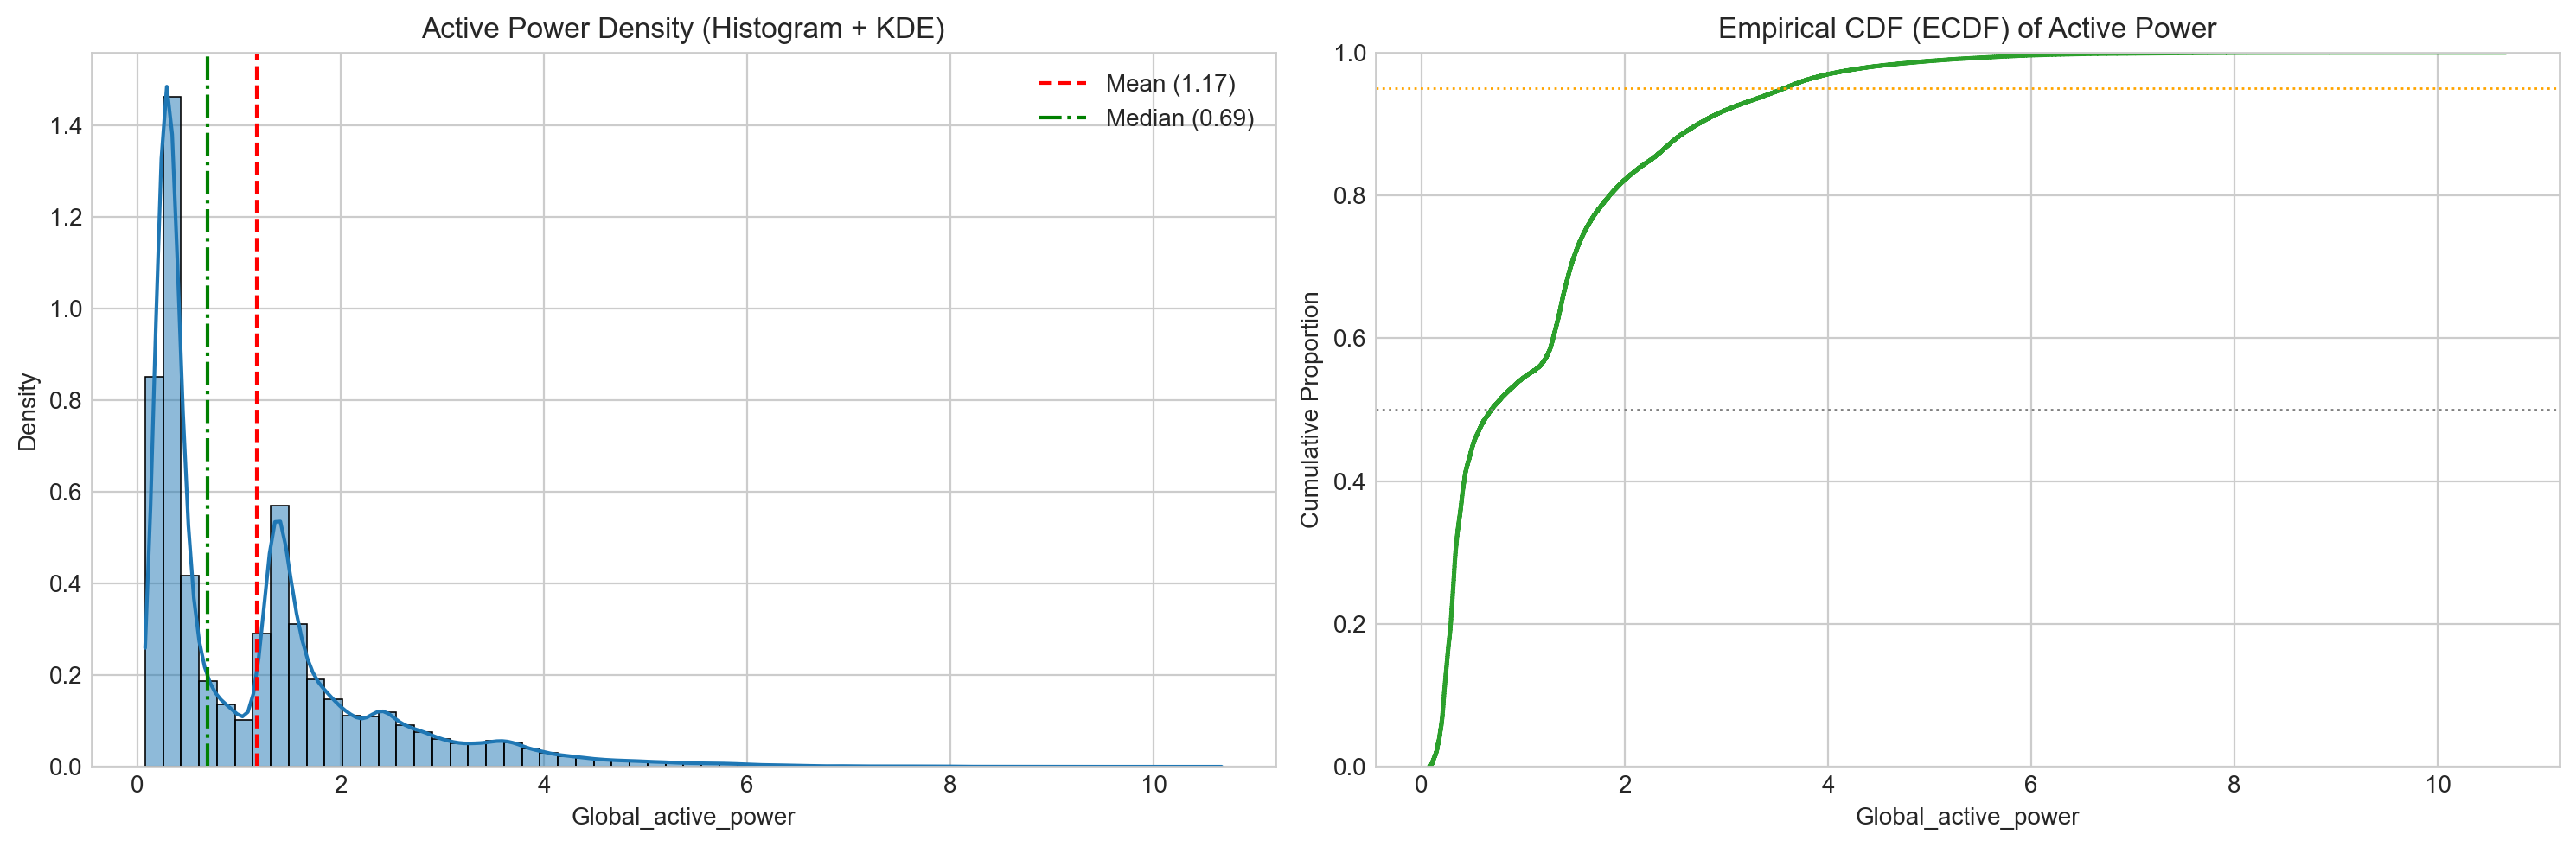

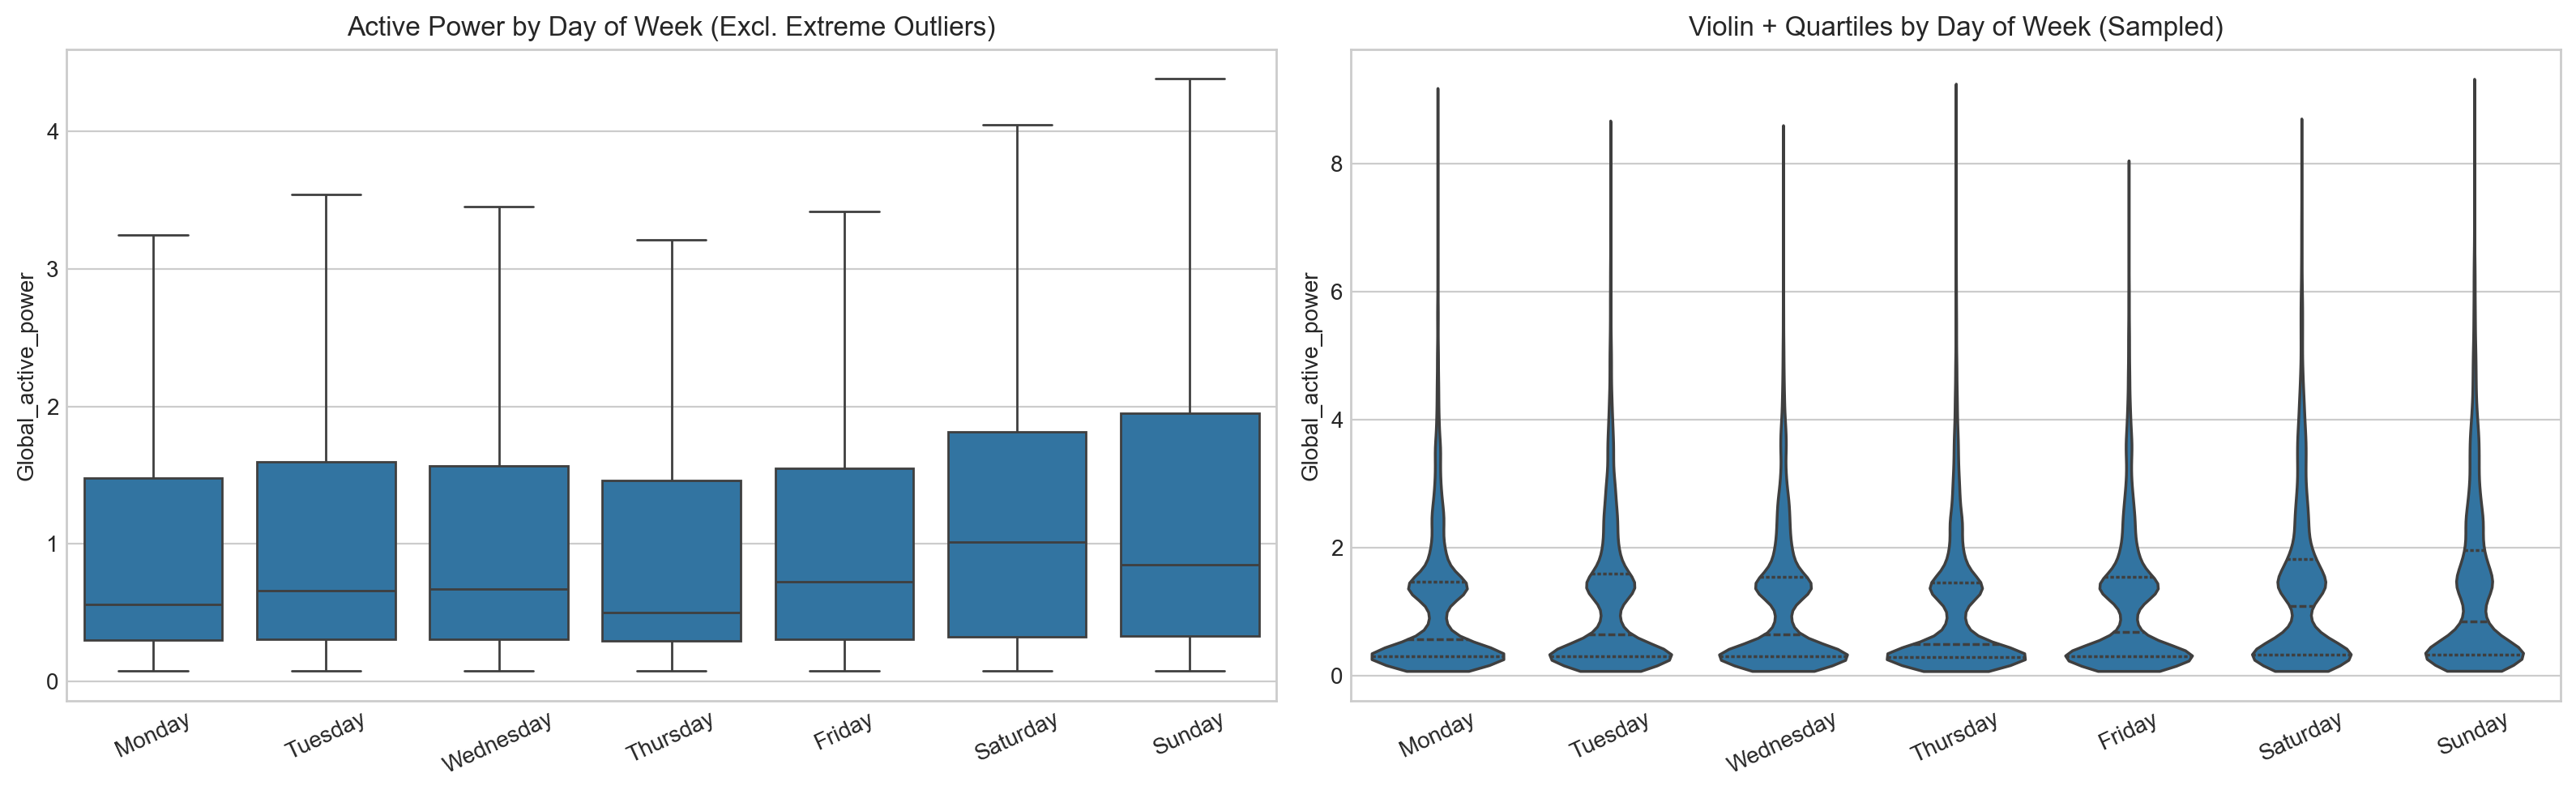

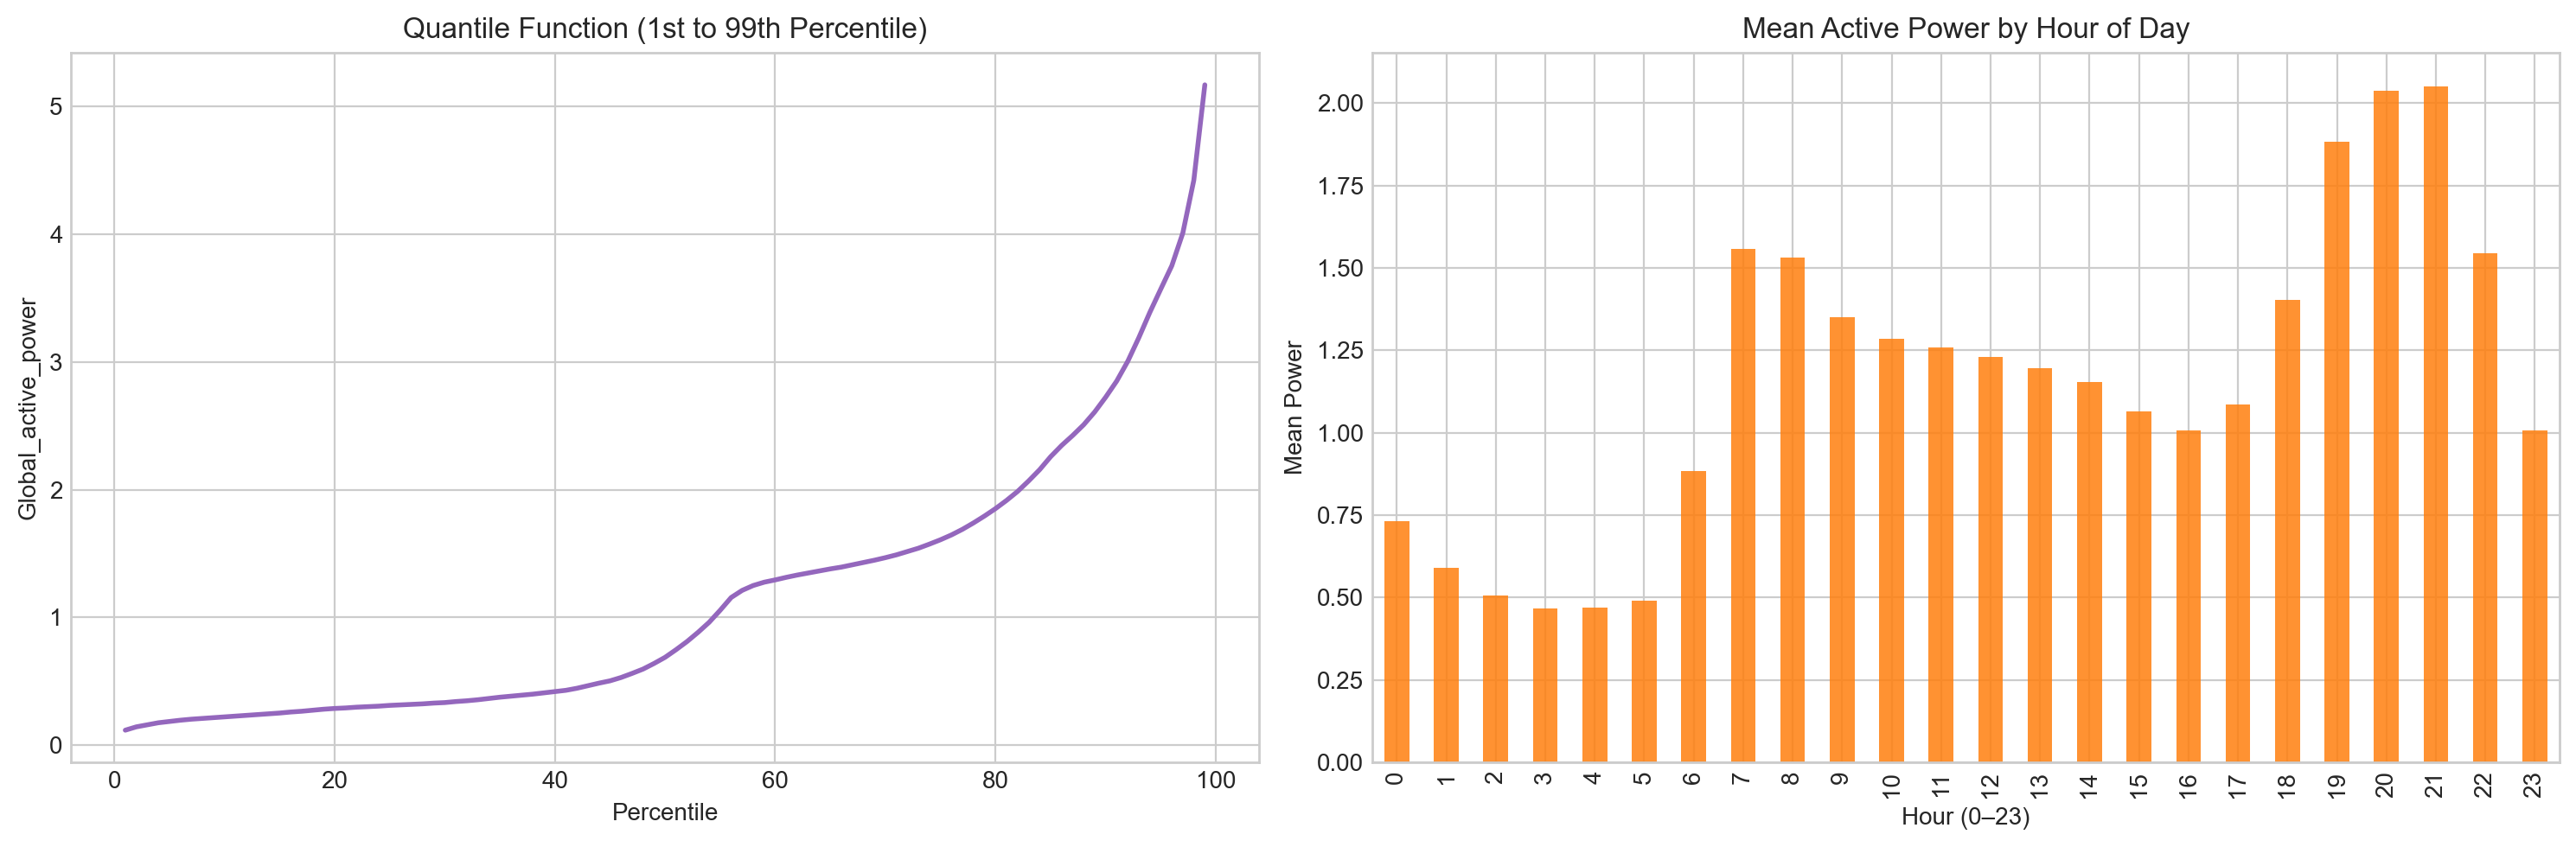

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if "df" not in globals() or "power_col" not in globals():
    PROJECT_ROOT = Path(r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION")
    df = pd.read_parquet(PROJECT_ROOT / "cleaned_household_power.parquet")
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)
    df = df.sort_index()
    power_col = next(
        (col for col in ["Global_active_power", "global_active_power"] if col in df.columns),
        df.columns[0]
    )
    df[power_col] = pd.to_numeric(df[power_col], errors="coerce")

if not isinstance(df.index, pd.DatetimeIndex):
    df.index = pd.to_datetime(df.index)

if "Hour" not in df.columns:
    df["Hour"] = df.index.hour
if "Weekday_Name" not in df.columns:
    df["Weekday_Name"] = df.index.day_name()

s = df[power_col].dropna()
mean_val = s.mean()
median_val = s.median()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

if "hourly_stats" not in globals():
    hourly_stats = df.groupby("Hour")[power_col].agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
        max_peak="max"
    ).round(3)

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

# --- Chart 1: Histogram + KDE & ECDF ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=200)

sns.histplot(s, bins=60, kde=True, stat="density", ax=axes[0], color="#1f77b4")
axes[0].axvline(mean_val, color="red", linestyle="--", linewidth=1.5, label=f"Mean ({mean_val:.2f})")
axes[0].axvline(median_val, color="green", linestyle="-.", linewidth=1.5, label=f"Median ({median_val:.2f})")
axes[0].set_title("Active Power Density (Histogram + KDE)")
axes[0].set_xlabel(power_col)
axes[0].legend()

sns.ecdfplot(s, ax=axes[1], color="#2ca02c", linewidth=1.8)
axes[1].axhline(0.50, color="gray", linestyle=":", linewidth=1)
axes[1].axhline(0.95, color="orange", linestyle=":", linewidth=1)
axes[1].set_title("Empirical CDF (ECDF) of Active Power")
axes[1].set_xlabel(power_col)
axes[1].set_ylabel("Cumulative Proportion")

plt.tight_layout()
plt.show()

# --- Chart 2: Boxplot & Violin Plot by Day of Week ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5), dpi=200)

sns.boxplot(data=df, x="Weekday_Name", y=power_col, order=day_order, showfliers=False, ax=axes[0])
axes[0].set_title("Active Power by Day of Week (Excl. Extreme Outliers)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)

sample_df = df.sample(n=min(100_000, len(df)), random_state=42)
sns.violinplot(data=sample_df, x="Weekday_Name", y=power_col, order=day_order, inner="quartile", cut=0, ax=axes[1])
axes[1].set_title("Violin + Quartiles by Day of Week (Sampled)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

# --- Chart 3: Quantile Chart & Hourly Mean Bar Chart ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=200)

pct_grid = np.linspace(0.01, 0.99, 99)
q_vals = s.quantile(pct_grid)
axes[0].plot(pct_grid * 100, q_vals.values, color="#9467bd", linewidth=2)
axes[0].set_title("Quantile Function (1st to 99th Percentile)")
axes[0].set_xlabel("Percentile")
axes[0].set_ylabel(power_col)

hourly_stats["mean"].plot(kind="bar", ax=axes[1], color="#ff7f0e", alpha=0.85)
axes[1].set_title("Mean Active Power by Hour of Day")
axes[1].set_xlabel("Hour (0–23)")
axes[1].set_ylabel("Mean Power")

plt.tight_layout()
plt.show()

=== 1. Normality & Distribution Fit Summary ===
Valid count (n): 967,828 | Mean: 1.1744 | SD: 1.1444
Skewness: 1.7022 | Excess Kurtosis: 3.5745
Shapiro-Wilk (n=5000): W=0.7945, p=4.19e-62
KS Test vs Fitted Normal: D=0.1921, p=4.11e-162
Fitted Lognormal (loc=0): shape(sigma)=0.9876, scale=0.7401
Fitted Exponential (loc=0): scale(1/lambda)=1.1744

=== 2. Operational Threshold Exceedance Probabilities ===
P(Power > 1.5 kW) = 0.2858 (28.58%) | Eve(19-21h): 58.24% vs Night(1-4h): 5.40% | Weekend: 34.91% vs Weekday: 26.02%
P(Power > 2.0 kW) = 0.1781 (17.81%) | Eve(19-21h): 43.21% vs Night(1-4h): 3.94% | Weekend: 23.02% vs Weekday: 15.72%
P(Power > 3.5 kW) = 0.0539 (5.39%) | Eve(19-21h): 14.45% vs Night(1-4h): 0.40% | Weekend: 8.14% vs Weekday: 4.28%

=== 3. Bayes' Theorem Check: P(Evening 19-21h | Power > 2.0 kW) ===
Prior P(Evening 19-21h): 0.1308
Likelihood P(Power > 2.0 | Evening): 0.4321
Marginal P(Power > 2.0): 0.1780
Posterior via Bayes: 0.3175 | Direct Empirical: 0.3175

=== 4. Serial

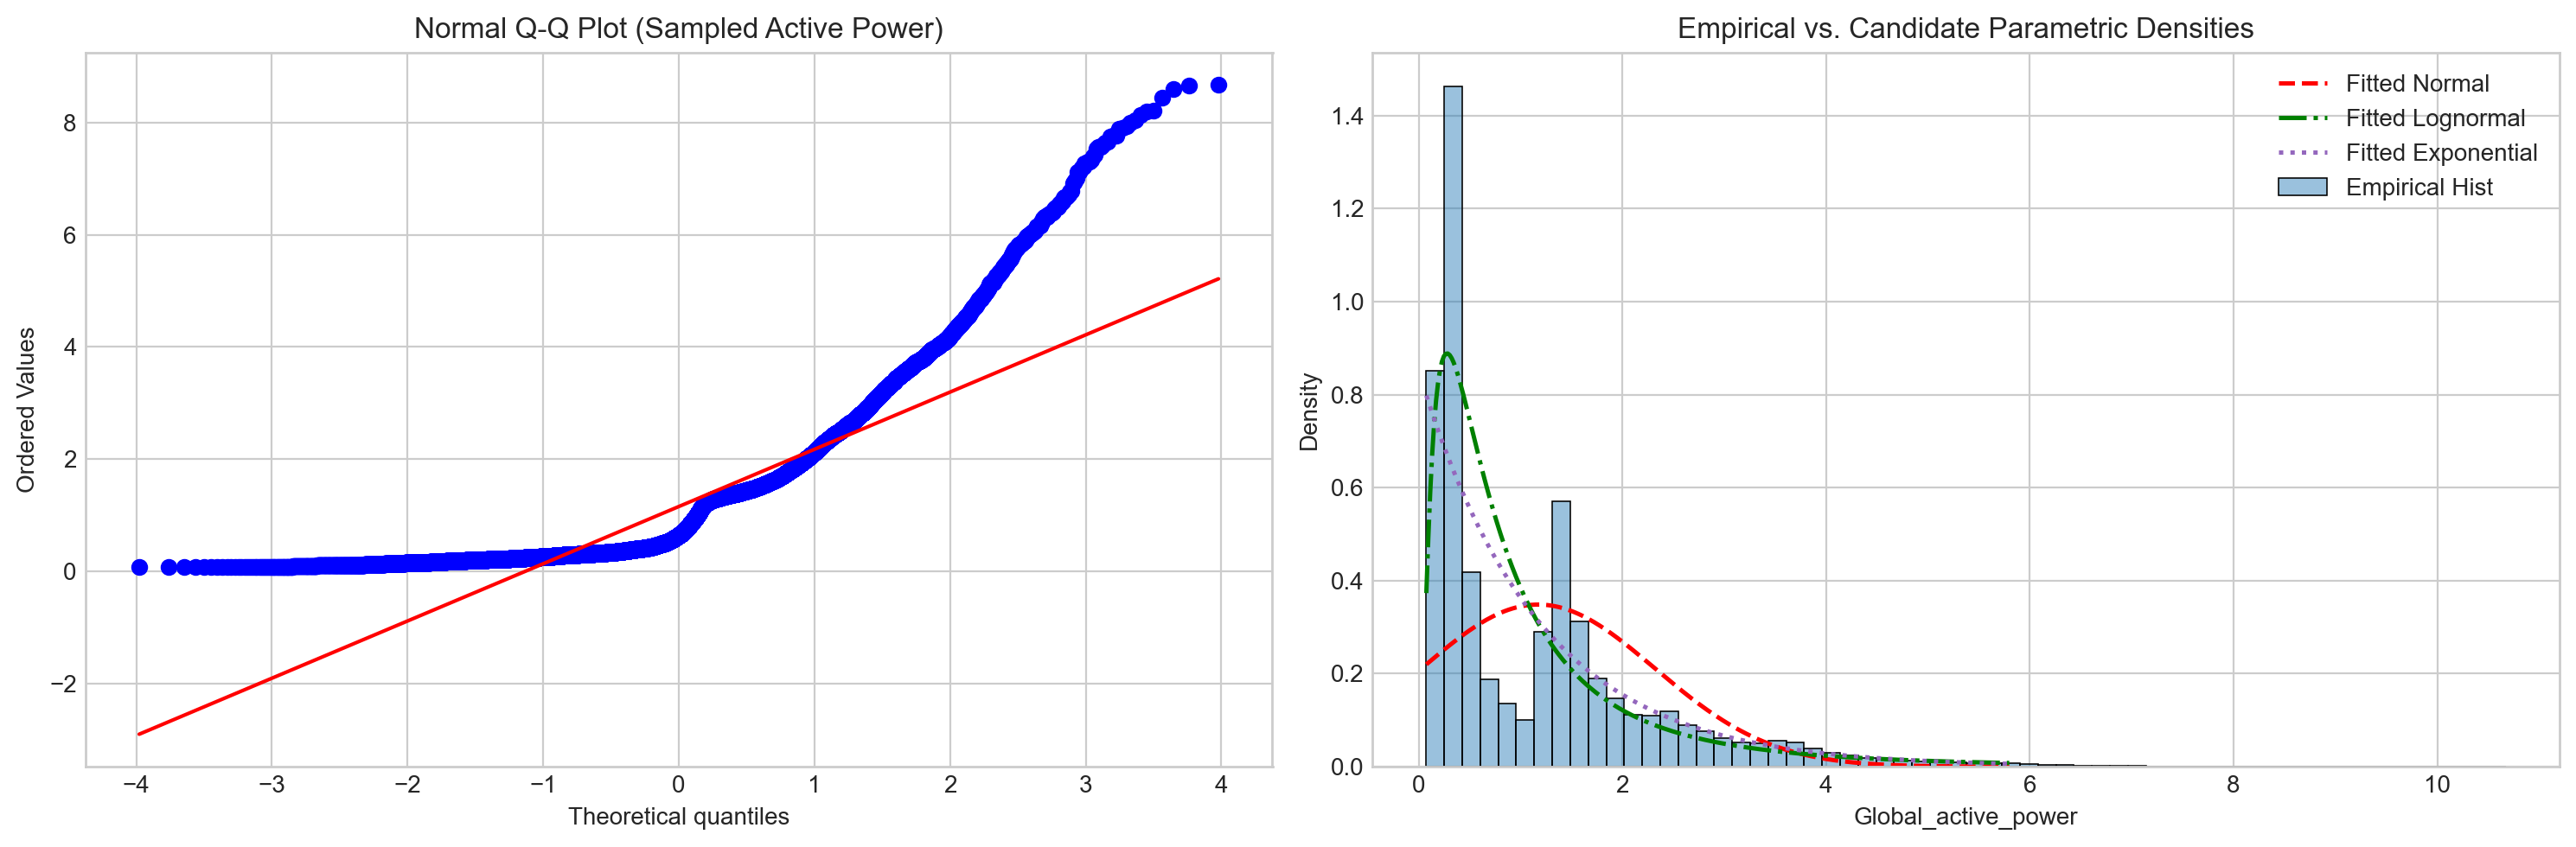

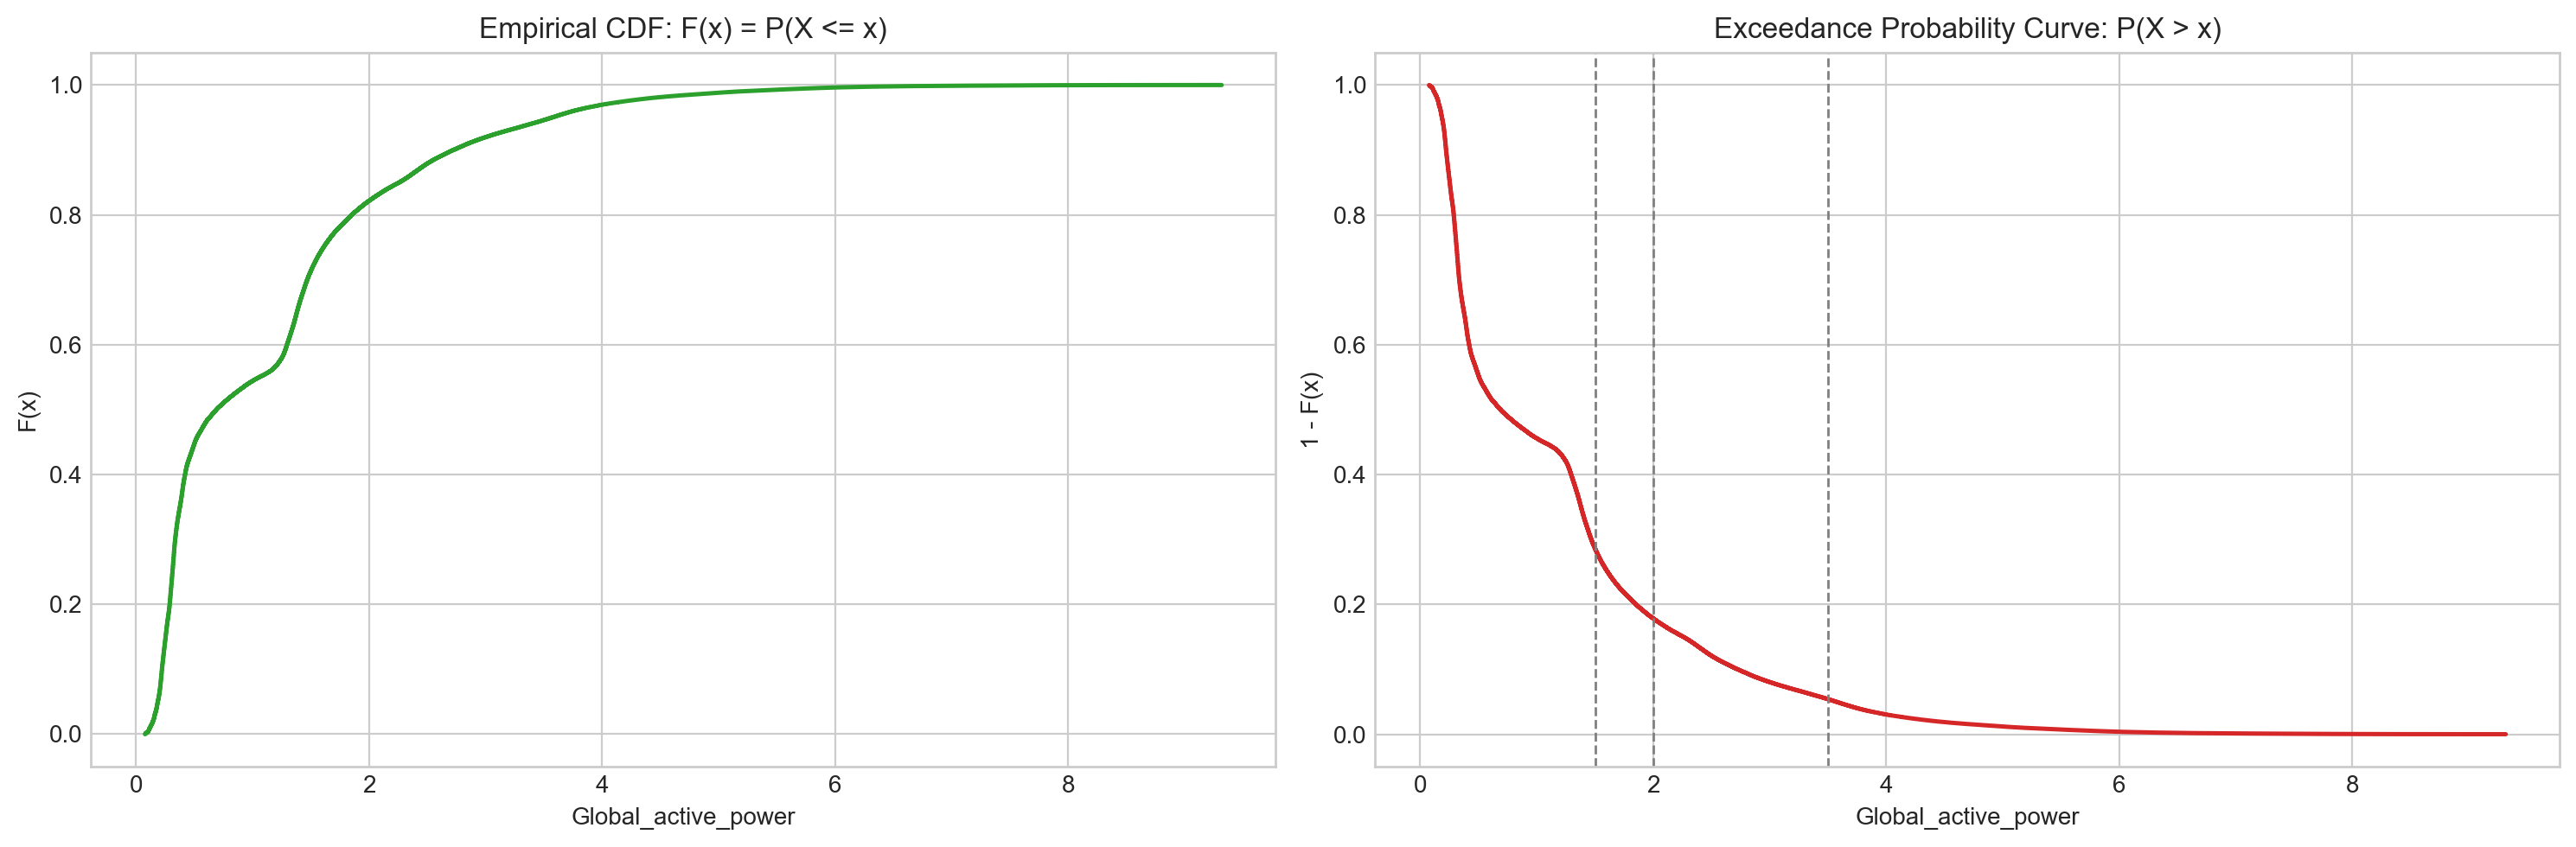

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# --- 0. Self-Healing Data & Feature Guard ---
if "df" not in globals() or "power_col" not in globals():
    PROJECT_ROOT = Path(
        r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION"
    )
    df = pd.read_parquet(PROJECT_ROOT / "cleaned_household_power.parquet")

if not isinstance(df.index, pd.DatetimeIndex):
    if "datetime" in df.columns:
        df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
        df = df.set_index("datetime")
    else:
        df.index = pd.to_datetime(df.index, errors="coerce")

df = df[~df.index.isna()].sort_index()

power_col = next(
    (c for c in ["Global_active_power", "global_active_power"] if c in df.columns),
    df.columns[0],
)
df[power_col] = pd.to_numeric(df[power_col], errors="coerce")

if "Hour" not in df.columns:
    df["Hour"] = df.index.hour
if "Weekday_Name" not in df.columns:
    df["Weekday_Name"] = df.index.day_name()
if "Is_Weekend" not in df.columns:
    df["Is_Weekend"] = df.index.dayofweek.isin([5, 6]).astype(int)

s = df[power_col].dropna()
n = len(s)
mean_val = float(s.mean())
std_val = float(s.std(ddof=1))

# --- 1. Normality & Parametric Fit Diagnostics ---
pos = s[s > 0]
norm_mu, norm_sigma = stats.norm.fit(s.to_numpy(dtype=float))
fitted_norm = stats.norm(loc=float(norm_mu), scale=float(norm_sigma))

lognorm_shape, lognorm_loc, lognorm_scale = stats.lognorm.fit(pos.to_numpy(dtype=float), floc=0)
expon_loc, expon_scale = stats.expon.fit(pos.to_numpy(dtype=float), floc=0)

# Subsample for Shapiro/KS clarity alongside full-sample moments
sample_test = s.sample(n=min(5000, n), random_state=42).to_numpy(dtype=float)
shapiro_stat, shapiro_p = stats.shapiro(sample_test)
ks_norm_stat, ks_norm_p = stats.kstest(sample_test, fitted_norm.cdf)

print("=== 1. Normality & Distribution Fit Summary ===")
print(f"Valid count (n): {n:,} | Mean: {mean_val:.4f} | SD: {std_val:.4f}")
print(f"Skewness: {s.skew():.4f} | Excess Kurtosis: {s.kurt():.4f}")
print(f"Shapiro-Wilk (n={len(sample_test)}): W={shapiro_stat:.4f}, p={shapiro_p:.2e}")
print(f"KS Test vs Fitted Normal: D={ks_norm_stat:.4f}, p={ks_norm_p:.2e}")
print(f"Fitted Lognormal (loc=0): shape(sigma)={lognorm_shape:.4f}, scale={lognorm_scale:.4f}")
print(f"Fitted Exponential (loc=0): scale(1/lambda)={expon_scale:.4f}")

# --- 2. Threshold Exceedance & Conditional Probabilities ---
thresholds = [1.5, 2.0, 3.5]
print("\n=== 2. Operational Threshold Exceedance Probabilities ===")
for tau in thresholds:
    p_exceed = float((s > tau).mean())
    p_cond_evening = float(df.loc[df["Hour"].isin([19, 20, 21]), power_col].gt(tau).mean())
    p_cond_night = float(df.loc[df["Hour"].isin([1, 2, 3, 4]), power_col].gt(tau).mean())
    p_cond_wknd = float(df.loc[df["Is_Weekend"] == 1, power_col].gt(tau).mean())
    p_cond_wkdy = float(df.loc[df["Is_Weekend"] == 0, power_col].gt(tau).mean())
    print(
        f"P(Power > {tau:.1f} kW) = {p_exceed:.4f} ({p_exceed*100:.2f}%) | "
        f"Eve(19-21h): {p_cond_evening*100:.2f}% vs Night(1-4h): {p_cond_night*100:.2f}% | "
        f"Weekend: {p_cond_wknd*100:.2f}% vs Weekday: {p_cond_wkdy*100:.2f}%"
    )

# Bayes' Theorem example: P(Evening Peak Window | Power > 2.0 kW)
tau_bayes = 2.0
is_eve = df["Hour"].isin([19, 20, 21])
is_high = df[power_col] > tau_bayes
p_eve = float(is_eve.mean())
p_high_given_eve = float(df.loc[is_eve, power_col].gt(tau_bayes).mean())
p_high = float(is_high.mean())
p_eve_given_high_bayes = (p_high_given_eve * p_eve) / p_high
p_eve_given_high_emp = float(is_eve[is_high].mean())

print("\n=== 3. Bayes' Theorem Check: P(Evening 19-21h | Power > 2.0 kW) ===")
print(f"Prior P(Evening 19-21h): {p_eve:.4f}")
print(f"Likelihood P(Power > 2.0 | Evening): {p_high_given_eve:.4f}")
print(f"Marginal P(Power > 2.0): {p_high:.4f}")
print(f"Posterior via Bayes: {p_eve_given_high_bayes:.4f} | Direct Empirical: {p_eve_given_high_emp:.4f}")

# --- 4. Serial Dependence & Standard Error Inflation ---
lag1_corr = float(s.autocorr(lag=1))
lag60_corr = float(s.autocorr(lag=60))  # 1-hour lag if 1-min data
se_iid = std_val / np.sqrt(n)

# Approximate effective sample size under AR(1)-like lag-1 persistence
if 0 < lag1_corr < 0.999:
    n_eff = n * (1 - lag1_corr) / (1 + lag1_corr)
else:
    n_eff = float(n)
se_corr_approx = std_val / np.sqrt(max(n_eff, 1.0))

# Block bootstrap of the sample mean (240-obs blocks) to observe empirical SE
rng = np.random.default_rng(42)
block_size = min(240, max(10, n // 50))
n_blocks = max(1, n // block_size)
blocks = s.iloc[: n_blocks * block_size].to_numpy(dtype=float).reshape(n_blocks, block_size)
boot_means = [
    blocks[rng.integers(0, n_blocks, size=n_blocks)].mean()
    for _ in range(300)
]
se_block_boot = float(np.std(boot_means, ddof=1))

print("\n=== 4. Serial Dependence & Standard Error Comparison ===")
print(f"Lag-1 Autocorrelation: {lag1_corr:.4f} | Lag-60 Autocorrelation: {lag60_corr:.4f}")
print(f"Naive i.i.d. SE(mean): {se_iid:.6f}")
print(f"Lag-1 Adjusted SE(mean): {se_corr_approx:.6f} (n_eff ≈ {n_eff:,.0f})")
print(f"Block Bootstrap SE(mean): {se_block_boot:.6f}")

# --- 5. Visual Evidence ---
plt.style.use(
    "seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default"
)

# Plot A: Q-Q Plot (Normal) & Fitted vs Empirical Density
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=200)

qq_sample = s.sample(n=min(20_000, n), random_state=42).to_numpy(dtype=float)
stats.probplot(qq_sample, dist="norm", plot=axes[0])
axes[0].set_title("Normal Q-Q Plot (Sampled Active Power)")

x_grid = np.linspace(max(0.01, float(pos.min())), float(s.quantile(0.995)), 300)
sns.histplot(s, bins=60, stat="density", ax=axes[1], color="#1f77b4", alpha=0.45, label="Empirical Hist")
axes[1].plot(x_grid, fitted_norm.pdf(x_grid), "r--", lw=1.8, label="Fitted Normal")
axes[1].plot(
    x_grid,
    stats.lognorm.pdf(x_grid, lognorm_shape, loc=lognorm_loc, scale=lognorm_scale),
    "g-.",
    lw=1.8,
    label="Fitted Lognormal",
)
axes[1].plot(
    x_grid,
    stats.expon.pdf(x_grid, loc=expon_loc, scale=expon_scale),
    color="#9467bd",
    ls=":",
    lw=1.8,
    label="Fitted Exponential",
)
axes[1].set_title("Empirical vs. Candidate Parametric Densities")
axes[1].set_xlabel(power_col)
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

# Plot B: Empirical CDF & Exceedance Probability Curve P(X > x)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=200)

sorted_vals = np.sort(s.to_numpy(dtype=float))
ecdf_y = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)
exceed_y = 1.0 - ecdf_y

axes[0].plot(sorted_vals[::50], ecdf_y[::50], color="#2ca02c", lw=1.8)
axes[0].set_title("Empirical CDF: F(x) = P(X <= x)")
axes[0].set_xlabel(power_col)
axes[0].set_ylabel("F(x)")

axes[1].plot(sorted_vals[::50], exceed_y[::50], color="#d62728", lw=1.8)
for tau in thresholds:
    axes[1].axvline(tau, color="gray", ls="--", lw=1)
axes[1].set_title("Exceedance Probability Curve: P(X > x)")
axes[1].set_xlabel(power_col)
axes[1].set_ylabel("1 - F(x)")

plt.tight_layout()
plt.show()

=== 1. Overall Point Estimates & 95% Block-Bootstrap CIs ===
Mean: 1.1744 kW | 95% Block CI: [1.1501, 1.2000] (i.i.d. 95% CI: [1.1718, 1.1766])
Median (50th): 0.6880 kW | 95% Block CI: [0.6359, 0.7500]
95th Percentile: 3.5700 kW | 95% Block CI: [3.5200, 3.6200]

=== 2. Average Hourly Power & 95% Block-Bootstrap CIs (Sample Hours) ===
 Hour  count     mean   ci_low  ci_high
    0  39792 0.732914 0.691445 0.785514
    3  37594 0.466447 0.440876 0.495103
    7  40873 1.557083 1.495129 1.617168
   12  40901 1.230024 1.173208 1.290667
   19  42169 1.883393 1.789904 1.966840
   20  42285 2.038170 1.959041 2.120782
   21  42208 2.050735 1.981156 2.117696
   23  40920 1.006959 0.957776 1.057899

=== 3. Weekend vs. Weekday Mean Difference (Weekend - Weekday) ===
Weekday Mean: 1.1048 kW | Weekend Mean: 1.3481 kW
Difference: +0.2433 kW | 95% Block-Bootstrap CI: [+0.1847, +0.3068]

=== 4. Hourly Sample Coverage Comparison ===
Max absolute hourly share gap (Random sample, n=10,000): 0.0051
      Po

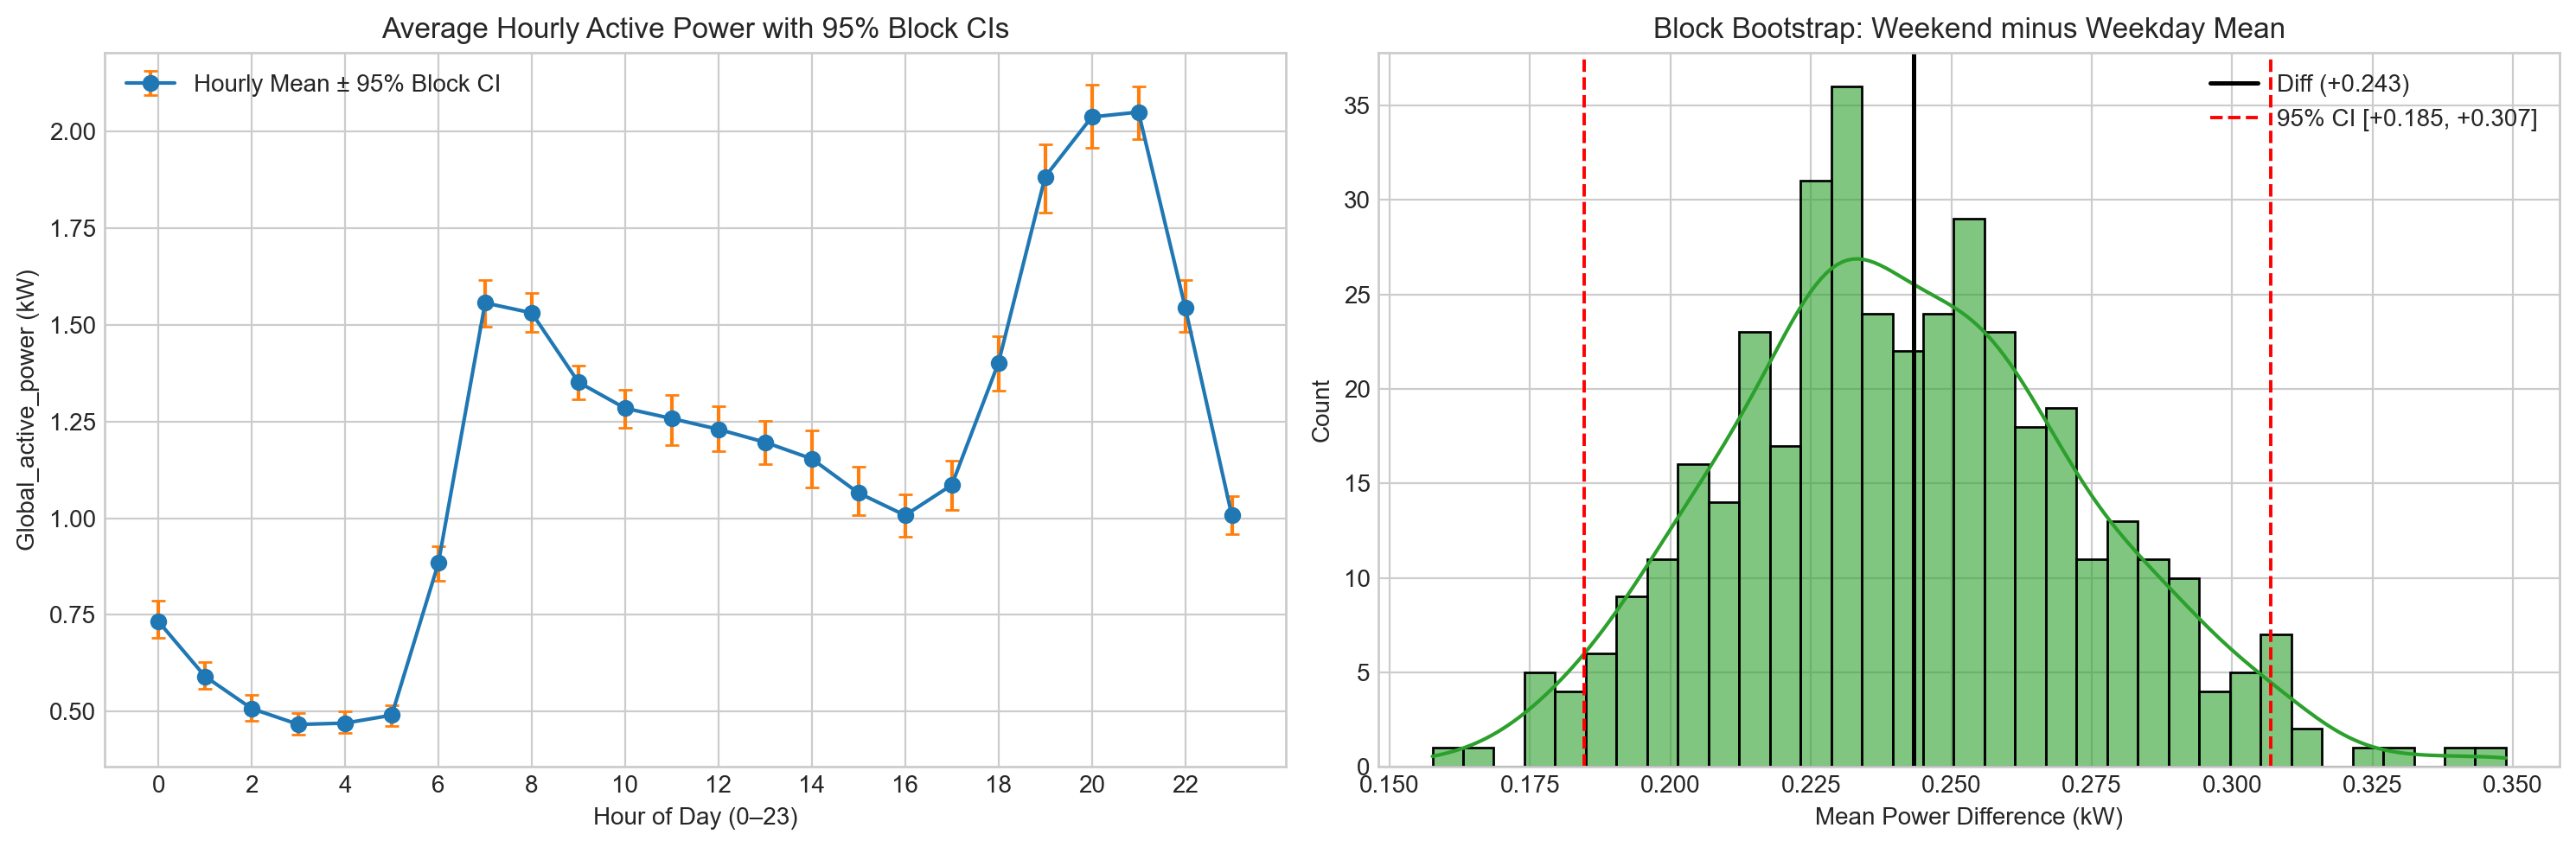

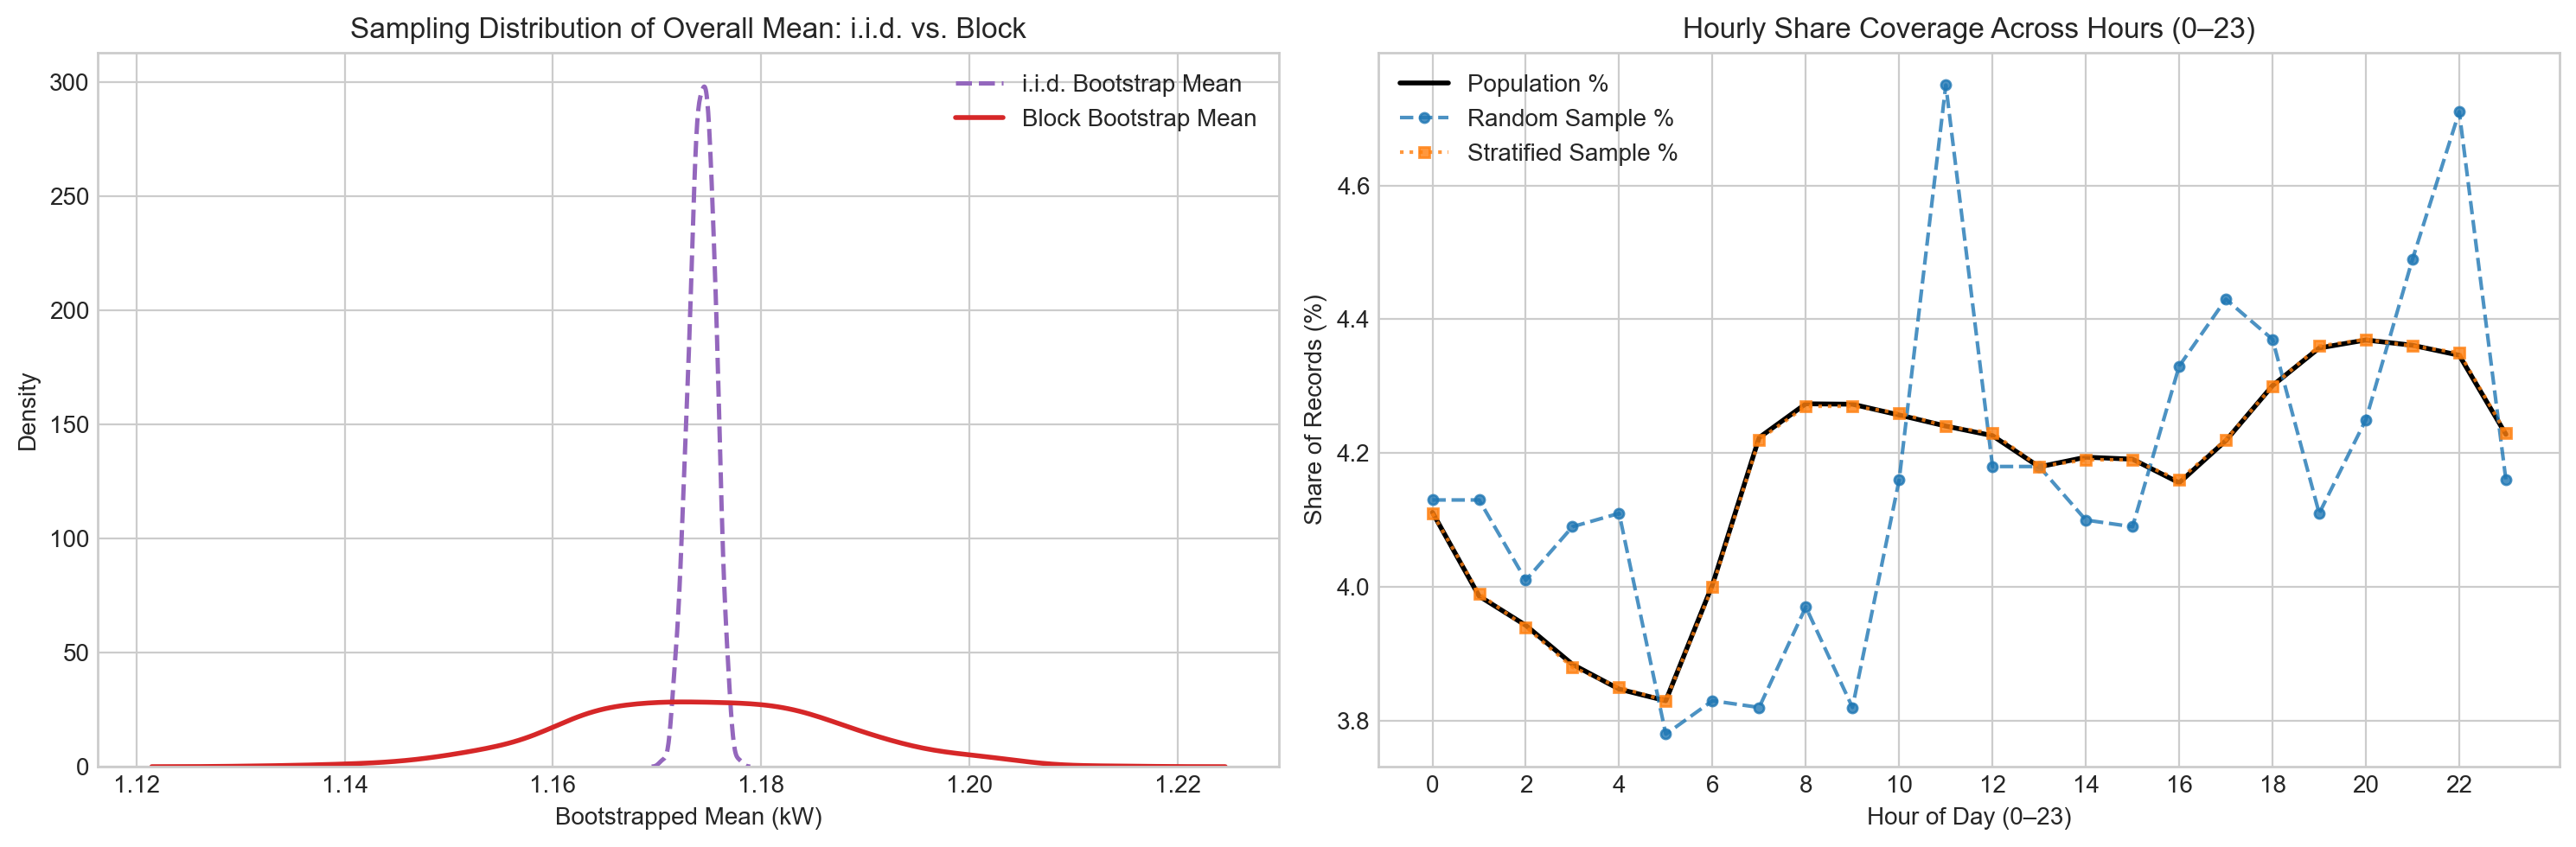

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 0. Self-Healing Data & Feature Guard ---
if "df" not in globals() or "power_col" not in globals():
    PROJECT_ROOT = Path(
        r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION"
    )
    df = pd.read_parquet(PROJECT_ROOT / "cleaned_household_power.parquet")

if not isinstance(df.index, pd.DatetimeIndex):
    if "datetime" in df.columns:
        df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
        df = df.set_index("datetime")
    else:
        df.index = pd.to_datetime(df.index, errors="coerce")

df = df[~df.index.isna()].sort_index()

power_col = next(
    (c for c in ["Global_active_power", "global_active_power"] if c in df.columns),
    df.columns[0],
)
df[power_col] = pd.to_numeric(df[power_col], errors="coerce")

if "Hour" not in df.columns:
    df["Hour"] = df.index.hour
if "Weekday_Name" not in df.columns:
    df["Weekday_Name"] = df.index.day_name()
if "Is_Weekend" not in df.columns:
    df["Is_Weekend"] = df.index.dayofweek.isin([5, 6]).astype(int)

valid_df = df.dropna(subset=[power_col]).copy()
s = valid_df[power_col].to_numpy(dtype=float)
n = len(s)
rng = np.random.default_rng(42)


def block_bootstrap_stat(values: np.ndarray, stat_fn, block_size: int = 240, n_boot: int = 400, seed: int = 42):
    """Block bootstrap preserving contiguous serial dependence within blocks."""
    g = np.random.default_rng(seed)
    b_size = min(max(1, block_size), len(values))
    n_blocks = max(1, len(values) // b_size)
    trimmed = values[: n_blocks * b_size].reshape(n_blocks, b_size)
    draws = np.empty(n_boot, dtype=float)
    for i in range(n_boot):
        idx = g.integers(0, n_blocks, size=n_blocks)
        sample_arr = trimmed[idx].ravel()
        draws[i] = stat_fn(sample_arr)
    low, high = np.percentile(draws, [2.5, 97.5])
    return float(stat_fn(values)), float(low), float(high), draws


# --- 1. Overall Mean, Median, and 95th Percentile (Block Bootstrap 95% CI) ---
block_len = 240  # ~4 hours if 1-minute intervals
mean_est, mean_lo, mean_hi, boot_means = block_bootstrap_stat(
    s, np.mean, block_size=block_len, n_boot=400, seed=42
)
med_est, med_lo, med_hi, _ = block_bootstrap_stat(
    s, np.median, block_size=block_len, n_boot=400, seed=43
)
p95_est, p95_lo, p95_hi, _ = block_bootstrap_stat(
    s, lambda x: np.percentile(x, 95), block_size=block_len, n_boot=400, seed=44
)

# Compare i.i.d. bootstrap spread vs block bootstrap spread on sample mean
iid_means = np.array([rng.choice(s, size=n, replace=True).mean() for _ in range(400)])
iid_lo, iid_hi = np.percentile(iid_means, [2.5, 97.5])

print("=== 1. Overall Point Estimates & 95% Block-Bootstrap CIs ===")
print(f"Mean: {mean_est:.4f} kW | 95% Block CI: [{mean_lo:.4f}, {mean_hi:.4f}] (i.i.d. 95% CI: [{iid_lo:.4f}, {iid_hi:.4f}])")
print(f"Median (50th): {med_est:.4f} kW | 95% Block CI: [{med_lo:.4f}, {med_hi:.4f}]")
print(f"95th Percentile: {p95_est:.4f} kW | 95% Block CI: [{p95_lo:.4f}, {p95_hi:.4f}]")

# --- 2. 95% Confidence Intervals for Average Hourly Power (Hours 0-23) ---
hourly_rows = []
for h in range(24):
    h_vals = valid_df.loc[valid_df["Hour"] == h, power_col].to_numpy(dtype=float)
    if len(h_vals) >= 20:
        h_mean, h_lo, h_hi, _ = block_bootstrap_stat(
            h_vals, np.mean, block_size=min(60, len(h_vals)), n_boot=250, seed=100 + h
        )
    else:
        h_mean = float(np.mean(h_vals))
        h_lo = h_hi = h_mean
    hourly_rows.append({"Hour": h, "count": len(h_vals), "mean": h_mean, "ci_low": h_lo, "ci_high": h_hi})

hourly_ci_df = pd.DataFrame(hourly_rows)
print("\n=== 2. Average Hourly Power & 95% Block-Bootstrap CIs (Sample Hours) ===")
print(hourly_ci_df.iloc[[0, 3, 7, 12, 19, 20, 21, 23]].to_string(index=False))

# --- 3. Weekday vs. Weekend Difference & Uncertainty ---
wkdy_vals = valid_df.loc[valid_df["Is_Weekend"] == 0, power_col].to_numpy(dtype=float)
wknd_vals = valid_df.loc[valid_df["Is_Weekend"] == 1, power_col].to_numpy(dtype=float)

diff_point = float(np.mean(wknd_vals) - np.mean(wkdy_vals))
n_b_diff = 400
b_size_d = 240
wkdy_blocks = wkdy_vals[: (len(wkdy_vals) // b_size_d) * b_size_d].reshape(-1, b_size_d)
wknd_blocks = wknd_vals[: (len(wknd_vals) // b_size_d) * b_size_d].reshape(-1, b_size_d)

diff_draws = np.empty(n_b_diff, dtype=float)
for i in range(n_b_diff):
    m_wknd = wknd_blocks[rng.integers(0, len(wknd_blocks), size=len(wknd_blocks))].mean()
    m_wkdy = wkdy_blocks[rng.integers(0, len(wkdy_blocks), size=len(wkdy_blocks))].mean()
    diff_draws[i] = m_wknd - m_wkdy

diff_lo, diff_hi = np.percentile(diff_draws, [2.5, 97.5])
print("\n=== 3. Weekend vs. Weekday Mean Difference (Weekend - Weekday) ===")
print(f"Weekday Mean: {np.mean(wkdy_vals):.4f} kW | Weekend Mean: {np.mean(wknd_vals):.4f} kW")
print(f"Difference: {diff_point:+.4f} kW | 95% Block-Bootstrap CI: [{diff_lo:+.4f}, {diff_hi:+.4f}]")

# --- 4. Sample Coverage by Time of Day (Random vs. Stratified) ---
sample_n = min(10_000, n)
rand_sample = valid_df.sample(n=sample_n, random_state=42)

strat_parts = []
for h, grp in valid_df.groupby("Hour", sort=True):
    k = max(1, int(round(sample_n * len(grp) / n)))
    k = min(k, len(grp))
    strat_parts.append(grp.sample(n=k, random_state=42))
strat_sample = pd.concat(strat_parts, axis=0)

pop_hour_share = valid_df["Hour"].value_counts(normalize=True).sort_index()
rand_hour_share = rand_sample["Hour"].value_counts(normalize=True).sort_index()
strat_hour_share = strat_sample["Hour"].value_counts(normalize=True).sort_index()

coverage_df = pd.DataFrame({
    "Population_Share": pop_hour_share,
    "Random_Sample_Share": rand_hour_share,
    "Stratified_Sample_Share": strat_hour_share,
    "Abs_Diff_Random": (rand_hour_share - pop_hour_share).abs(),
})
print("\n=== 4. Hourly Sample Coverage Comparison ===")
print(f"Max absolute hourly share gap (Random sample, n={sample_n:,}): {coverage_df['Abs_Diff_Random'].max():.4f}")
print(coverage_df.head(6).round(4).to_string())

# --- 5. Visual Evidence ---
plt.style.use(
    "seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default"
)

# Chart 1: Hourly Mean 95% CI Error Bars & Weekday-Weekend Diff Bootstrap Distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=200)

yerr_lo = hourly_ci_df["mean"] - hourly_ci_df["ci_low"]
yerr_hi = hourly_ci_df["ci_high"] - hourly_ci_df["mean"]
axes[0].errorbar(
    hourly_ci_df["Hour"],
    hourly_ci_df["mean"],
    yerr=[yerr_lo, yerr_hi],
    fmt="o-",
    color="#1f77b4",
    ecolor="#ff7f0e",
    elinewidth=1.5,
    capsize=3,
    label="Hourly Mean ± 95% Block CI",
)
axes[0].set_title("Average Hourly Active Power with 95% Block CIs")
axes[0].set_xlabel("Hour of Day (0–23)")
axes[0].set_ylabel(f"{power_col} (kW)")
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend()

sns.histplot(diff_draws, bins=35, kde=True, ax=axes[1], color="#2ca02c", alpha=0.6)
axes[1].axvline(diff_point, color="black", linestyle="-", linewidth=1.8, label=f"Diff ({diff_point:+.3f})")
axes[1].axvline(diff_lo, color="red", linestyle="--", linewidth=1.4, label=f"95% CI [{diff_lo:+.3f}, {diff_hi:+.3f}]")
axes[1].axvline(diff_hi, color="red", linestyle="--", linewidth=1.4)
axes[1].set_title("Block Bootstrap: Weekend minus Weekday Mean")
axes[1].set_xlabel("Mean Power Difference (kW)")
axes[1].legend()

plt.tight_layout()
plt.show()

# Chart 2: i.i.d. vs Block Bootstrap Mean Spread & Hourly Sample Coverage
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=200)

sns.kdeplot(iid_means, ax=axes[0], color="#9467bd", linestyle="--", linewidth=1.8, label="i.i.d. Bootstrap Mean")
sns.kdeplot(boot_means, ax=axes[0], color="#d62728", linestyle="-", linewidth=2.0, label="Block Bootstrap Mean")
axes[0].set_title("Sampling Distribution of Overall Mean: i.i.d. vs. Block")
axes[0].set_xlabel("Bootstrapped Mean (kW)")
axes[0].legend()

axes[1].plot(coverage_df.index, coverage_df["Population_Share"] * 100, "k-", lw=2, label="Population %")
axes[1].plot(coverage_df.index, coverage_df["Random_Sample_Share"] * 100, "o--", ms=4, alpha=0.8, label="Random Sample %")
axes[1].plot(coverage_df.index, coverage_df["Stratified_Sample_Share"] * 100, "s:", ms=4, alpha=0.8, label="Stratified Sample %")
axes[1].set_title("Hourly Share Coverage Across Hours (0–23)")
axes[1].set_xlabel("Hour of Day (0–23)")
axes[1].set_ylabel("Share of Records (%)")
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend()

plt.tight_layout()
plt.show()